1. Parsing Kepler Spectral Response PDF...
   -> Loaded 911 wavelength rows (150 nm to 1060 nm).

2. Parsing HIP 60202 Photometric Light Curve PDF...
   -> Loaded 98 verified observations (out of 104 total).

3. Training ML Model & Simulating Kepler Observations...
   -> Light Curve Model RMSE: 0.01109 mag
   -> Mean Visible Transmission: Channel 1 = 0.3886 | Channel 29 = 0.3883

Success!
Saved At/Users/aadityasunildhamdhere/Desktop/P-B/D/nasa_model_output.png


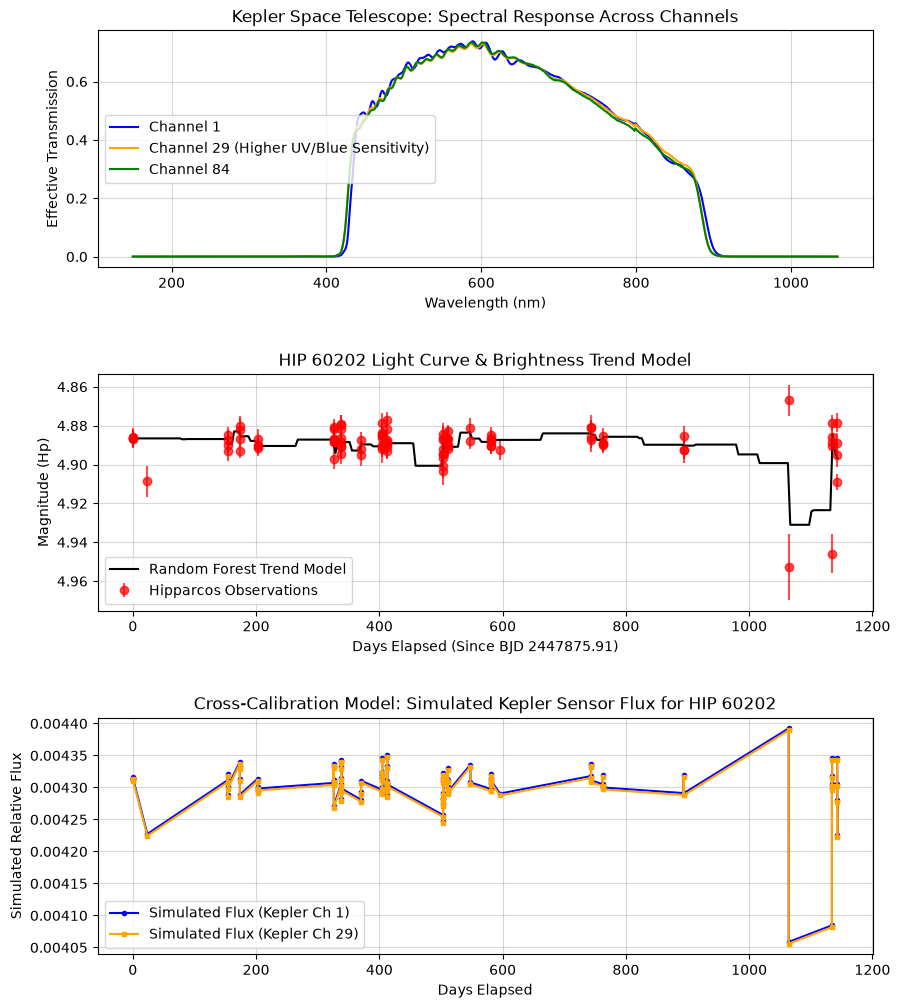

In [8]:
import io
import re
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pypdf import PdfReader
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split

# ==============================================================================
# STEP 1: EXTRACT & CLEAN KEPLER SPECTRAL RESPONSE DATA
# ==============================================================================
print("1. Parsing Kepler Spectral Response PDF...")
kepler_path = "/Users/aadityasunildhamdhere/Desktop/P-B/D/kplr_2015120120_spectral_response.pdf"
kepler_reader = PdfReader(kepler_path)
raw_kepler = "\n".join([page.extract_text() for page in kepler_reader.pages])

# Fix PDF line-wrapping inside scientific notation (e.g., '3.67E-\n09' -> '3.67E-09')
clean_kepler = re.sub(r"E-\s*\n\s*", "E-", raw_kepler)
clean_kepler = re.sub(r"E\+\s*\n\s*", "E+", clean_kepler)

kepler_rows = []
for line in clean_kepler.splitlines():
    line = line.strip()
    # Skip comment lines and page headers; keep comma-separated data rows
    if (
        line
        and not line.startswith("#")
        and not line.startswith("###")
        and "," in line
    ):
        parts = line.split(",")
        if len(parts) == 85:  # 1 Wavelength column + 84 Channel columns
            kepler_rows.append(line)

kepler_cols = ["Wavelength_nm"] + [f"Channel_{i}" for i in range(1, 85)]
df_kepler = pd.read_csv(io.StringIO("\n".join(kepler_rows)), names=kepler_cols)
df_kepler = df_kepler.apply(pd.to_numeric, errors="coerce").dropna()

print(
    f"   -> Loaded {len(df_kepler)} wavelength rows"
    f" ({df_kepler['Wavelength_nm'].min()} nm to"
    f" {df_kepler['Wavelength_nm'].max()} nm)."
)


# ==============================================================================
# STEP 2: EXTRACT & CLEAN HIP 60202 LIGHT CURVE DATA
# ==============================================================================
print("\n2. Parsing HIP 60202 Photometric Light Curve PDF...")
hip_path = "/Users/aadityasunildhamdhere/Desktop/P-B/D/UID_0060202_PLC_001.tbl.pdf"
hip_reader = PdfReader(hip_path)
raw_hip = "\n".join([page.extract_text() for page in hip_reader.pages])

hip_rows = []
for line in raw_hip.splitlines():
    parts = line.strip().split()
    # Data rows have 5 columns and start with BJD timestamps around 244xxxx
    if len(parts) == 5 and parts[0].startswith("244"):
        hip_rows.append(parts)

hip_cols = [
    "BJD",
    "Magnitude",
    "Magnitude_Uncertainty",
    "Data_Quality_Flag",
    "Accepted",
]
df_hip = pd.DataFrame(hip_rows, columns=hip_cols).astype(float)

# Keep only NASA-accepted, high-quality observations (Accepted == 1)
df_hip_clean = df_hip[df_hip["Accepted"] == 1].copy()
df_hip_clean["Days_Elapsed"] = (
    df_hip_clean["BJD"] - df_hip_clean["BJD"].min()
)

print(
    f"   -> Loaded {len(df_hip_clean)} verified observations (out of"
    f" {len(df_hip)} total)."
)


# ==============================================================================
# STEP 3: BUILD THE MODEL (KEPLER THROUGHPUT + STELLAR FLUX SIMULATION)
# ==============================================================================
print("\n3. Training ML Model & Simulating Kepler Observations...")

# Model A: Train a Random Forest Regressor to model HIP 60202's baseline brightness trend
X = df_hip_clean[["Days_Elapsed"]]
y = df_hip_clean["Magnitude"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

predictions = model.predict(X_test)
rmse = np.sqrt(mean_squared_error(y_test, predictions))
print(f"   -> Light Curve Model RMSE: {rmse:.5f} mag")

# Model B: Cross-instrument simulation using Kepler's Spectral Response
# Calculate mean effective transmission across the visible spectrum (400-723 nm) for Channel 1 vs Channel 29
visible_kepler = df_kepler[df_kepler["Wavelength_nm"] >= 400]
mean_trans_ch1 = visible_kepler["Channel_1"].mean()
mean_trans_ch29 = visible_kepler["Channel_29"].mean()

# Convert astronomical magnitude to relative flux: Flux = 10^(-0.4 * Mag)
df_hip_clean["Relative_Flux"] = 10 ** (-0.4 * df_hip_clean["Magnitude"])

# Simulate detected photon flux in Kepler Channel 1 vs Channel 29
df_hip_clean["Kepler_Ch1_Detected_Flux"] = (
    df_hip_clean["Relative_Flux"] * mean_trans_ch1
)
df_hip_clean["Kepler_Ch29_Detected_Flux"] = (
    df_hip_clean["Relative_Flux"] * mean_trans_ch29
)

print(
    f"   -> Mean Visible Transmission: Channel 1 = {mean_trans_ch1:.4f} |"
    f" Channel 29 = {mean_trans_ch29:.4f}"
)


# ==============================================================================
# STEP 4: GENERATE VISUALIZATIONS FOR HACKATHON PRESENTATION
# ==============================================================================
fig, axes = plt.subplots(3, 1, figsize=(10, 12))
plt.subplots_adjust(hspace=0.45)

# Plot 1: Kepler Spectral Response Curves
axes[0].plot(
    df_kepler["Wavelength_nm"],
    df_kepler["Channel_1"],
    label="Channel 1",
    color="blue",
)
axes[0].plot(
    df_kepler["Wavelength_nm"],
    df_kepler["Channel_29"],
    label="Channel 29 (Higher UV/Blue Sensitivity)",
    color="orange",
)
axes[0].plot(
    df_kepler["Wavelength_nm"],
    df_kepler["Channel_84"],
    label="Channel 84",
    color="green",
)
axes[0].set_title(
    "Kepler Space Telescope: Spectral Response Across Channels", fontsize=12
)
axes[0].set_xlabel("Wavelength (nm)")
axes[0].set_ylabel("Effective Transmission")
axes[0].legend()
axes[0].grid(True, alpha=0.5)

# Plot 2: HIP 60202 Light Curve + ML Trend Prediction
days_grid = np.linspace(0, df_hip_clean["Days_Elapsed"].max(), 300).reshape(
    -1, 1
)
predicted_curve = model.predict(
    pd.DataFrame(days_grid, columns=["Days_Elapsed"])
)

axes[1].errorbar(
    df_hip_clean["Days_Elapsed"],
    df_hip_clean["Magnitude"],
    yerr=df_hip_clean["Magnitude_Uncertainty"],
    fmt="o",
    color="red",
    alpha=0.7,
    label="Hipparcos Observations",
)
axes[1].plot(
    days_grid,
    predicted_curve,
    color="black",
    linewidth=1.5,
    label="Random Forest Trend Model",
)
axes[1].invert_yaxis()  # Lower magnitude = brighter star
axes[1].set_title(
    "HIP 60202 Light Curve & Brightness Trend Model", fontsize=12
)
axes[1].set_xlabel("Days Elapsed (Since BJD 2447875.91)")
axes[1].set_ylabel("Magnitude (Hp)")
axes[1].legend()
axes[1].grid(True, alpha=0.5)

# Plot 3: Simulated Kepler Sensor Output for HIP 60202
axes[2].plot(
    df_hip_clean["Days_Elapsed"],
    df_hip_clean["Kepler_Ch1_Detected_Flux"],
    "o-",
    label="Simulated Flux (Kepler Ch 1)",
    color="blue",
    markersize=3,
)
axes[2].plot(
    df_hip_clean["Days_Elapsed"],
    df_hip_clean["Kepler_Ch29_Detected_Flux"],
    "s-",
    label="Simulated Flux (Kepler Ch 29)",
    color="orange",
    markersize=3,
)
axes[2].set_title(
    "Cross-Calibration Model: Simulated Kepler Sensor Flux for HIP 60202",
    fontsize=12
)
axes[2].set_xlabel("Days Elapsed")
axes[2].set_ylabel("Simulated Relative Flux")
axes[2].legend()
axes[2].grid(True, alpha=0.5)

output_image = "/Users/aadityasunildhamdhere/Desktop/P-B/D/nasa_model_output.png"
plt.savefig(output_image, dpi=300)

print("\nSuccess!")
print(f'Saved At{output_image}')
plt.show()
